# 15-Minute Walkability Analysis in Shanghai

## Objective
The goal of this project is to evaluate how well Shanghai villages comply with the "15-minute rule", which states that essential services (schools, clinics, parks, markets, etc.) should be reachable within a 15-minute walk.

## Methodology
We will:
- Create walking distance buffers of 5, 10, and 15 minutes around each village.
- Count the number of Points of Interest (POIs) within these buffers.
- Normalize the data and calculate a composite walkability score.
- Visualize the spatial distribution of accessibility across Shanghai.

## Assumption
Average walking speed is set at 1.31 meters per second (based on adults aged 20–39).


In [1]:
# Import libraries for geospatial and statistical analysis
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neighbors import BallTree
from sklearn.preprocessing import MinMaxScaler
from scipy import stats
import statsmodels.api as sm

# Optional: basemap library (comment if not installed)
# import contextily as cx

# Set plot style
sns.set_style("white")


In [2]:
# Load the GeoJSON file containing village geometries
village_file = 'sh-villages.geojson'
villages = gpd.read_file(village_file)

# Display basic information about the dataset
villages.info()
villages.head()


<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 5614 entries, 0 to 5613
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   ad_code   5614 non-null   object  
 1   name      5614 non-null   object  
 2   multi     5614 non-null   float64 
 3   ismulti   5614 non-null   object  
 4   geometry  5614 non-null   geometry
dtypes: float64(1), geometry(1), object(3)
memory usage: 219.4+ KB


,ad_code,name,multi,ismulti,geometry
0,310104017001,习勤社区,1.0,N,"POLYGON ((121.42336 31.16744, 121.42065 31.167..."
1,310112006036,古龙四村社区,1.0,N,"POLYGON ((121.40327 31.15131, 121.39904 31.149..."
2,310112101051,香树丽舍社区,1.0,N,"POLYGON ((121.37217 31.12649, 121.36911 31.125..."
3,310113101011,罗新社区,1.0,N,"POLYGON ((121.34649 31.42434, 121.34347 31.423..."
4,310113101012,金星第二社区,1.0,N,"POLYGON ((121.35246 31.42298, 121.3476 31.4215..."


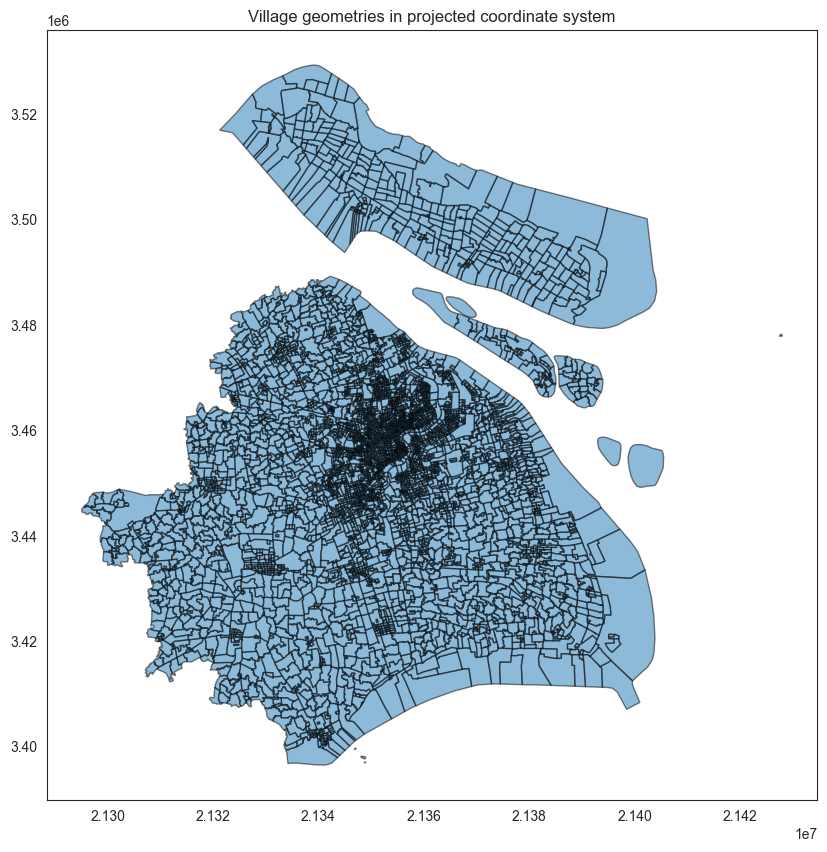

In [3]:
# Reproject the GeoDataFrame to a metric coordinate system (EPSG:4576 is suitable for Shanghai)
villages = villages.to_crs(epsg=4576)

# Optional: plot a sample of village geometries
villages.plot(figsize=(10, 10), edgecolor='black', alpha=0.5)
plt.title('Village geometries in projected coordinate system')
plt.show()


In [4]:
# Define walking speed in meters per second
walking_speed = 1.31  # average speed for adults aged 20–39

# Compute walking distances in meters
dist_5min = 5 * 60 * walking_speed
dist_10min = 10 * 60 * walking_speed
dist_15min = 15 * 60 * walking_speed

# Create buffers around each village geometry
villages['buffer_5'] = villages.geometry.buffer(dist_5min)
villages['buffer_10'] = villages.geometry.buffer(dist_10min)
villages['buffer_15'] = villages.geometry.buffer(dist_15min)


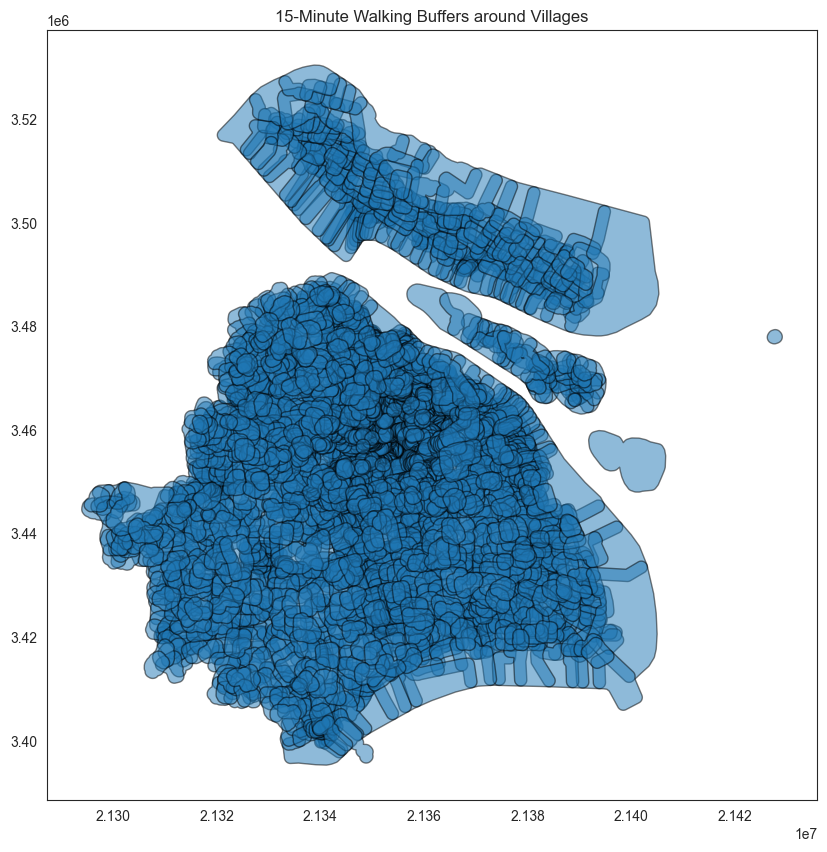

In [5]:
# Plot 15-minute buffers as an example
villages.set_geometry('buffer_15').plot(figsize=(12, 10), edgecolor='black', alpha=0.5)
plt.title('15-Minute Walking Buffers around Villages')
plt.show()


In [6]:
# Load Points of Interest (POI) shapefile
poi_file = '上海市-POI.shp'  # make sure this file is in your working directory
pois = gpd.read_file(poi_file, encoding='utf-8')

# Check basic info about the POI dataset
pois.info()
pois.head()


<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1754933 entries, 0 to 1754932
Data columns (total 22 columns):
 #   Column      Dtype   
---  ------      -----   
 0   id          object  
 1   pname       object  
 2   pcode       int64   
 3   cityname    object  
 4   citycode    int64   
 5   adname      object  
 6   adcode      int64   
 7   name        object  
 8   address     object  
 9   location    object  
 10  tel         object  
 11  business_a  object  
 12  bigType     object  
 13  midType     object  
 14  smallType   object  
 15  typecode    object  
 16  timestamp   object  
 17  gcjLng      float64 
 18  gcjLat      float64 
 19  wgs84Lng    float64 
 20  wgs84Lat    float64 
 21  geometry    geometry
dtypes: float64(4), geometry(1), int64(3), object(14)
memory usage: 294.6+ MB


,id,pname,pcode,cityname,citycode,adname,adcode,name,address,location,...,bigType,midType,smallType,typecode,timestamp,gcjLng,gcjLat,wgs84Lng,wgs84Lat,geometry
0,7ccbf68a-f5bd-3ce8-ac9c-28f41a1afe57,上海市,310000,上海市,21,松江区,310117,新弘国际城新弘墅园471号楼,月台路555弄,"121.325438,31.070551",...,地名地址信息,门牌信息,楼栋号,190403,2024-01-23 04:59:38,121.325438,31.070551,121.320915,31.072567,POINT (121.32092 31.07257)
1,4726031b-a1f2-3a46-bcef-dac9d75f40b8,上海市,310000,上海市,21,松江区,310117,新弘国际城新弘墅园469号楼,月台路555弄,"121.325439,31.070551",...,地名地址信息,门牌信息,楼栋号,190403,2024-01-31 13:57:17,121.325439,31.070551,121.320916,31.072567,POINT (121.32092 31.07257)
2,02b8309c-5c78-3ac7-b143-19dcb033bfd5,上海市,310000,上海市,21,松江区,310117,新弘国际城新弘墅园208号,月台路555弄,"121.325363,31.071841",...,地名地址信息,门牌信息,楼栋号,190403,2024-02-01 23:41:35,121.325363,31.071841,121.320840,31.073856,POINT (121.32084 31.07386)
3,7a52b8c0-3ad6-38cd-99a3-e26ea27b4e3f,上海市,310000,上海市,21,松江区,310117,新弘国际城新弘墅园372号,月台路555弄,"121.325863,31.071555",...,地名地址信息,门牌信息,楼栋号,190403,2024-01-20 09:11:13,121.325863,31.071555,121.321339,31.073569,POINT (121.32134 31.07357)
4,54d71d32-2a56-3376-a9a2-5f20e995c797,上海市,310000,上海市,21,松江区,310117,新弘国际城新弘墅园438号,月台路555弄,"121.325979,31.071014",...,地名地址信息,门牌信息,楼栋号,190403,2024-02-15 12:30:49,121.325979,31.071014,121.321454,31.073028,POINT (121.32145 31.07303)


In [7]:
# Select POIs relevant for urgent daily needs (5-minute walk)
pois_5min = pois[
    (pois['typecode'] == '070000') |  # residential areas
    (pois['typecode'] == '060200') |  # schools
    (pois['typecode'] == '060705') |  # convenience stores
    (pois['typecode'] == '110101') |  # clinics
    (pois['typecode'] == '141204') |  # parks/green spaces
    (pois['typecode'] == '080501')    # public toilets
]

# Check how many POIs we selected
pois_5min['typecode'].value_counts()


typecode
070000    27618
060200    20213
060705     2005
141204     1780
110101     1199
080501      839
Name: count, dtype: int64

In [8]:
# Perform spatial join between 5-minute buffers and relevant POIs
villages_5min = villages.set_geometry('buffer_5').sjoin(pois_5min.to_crs(villages.crs))

# Count POIs per village
poi_count_5min = villages_5min.groupby(villages_5min.index).count()

# Store the result in a new column
villages['5min'] = poi_count_5min['ad_code']

# Fill NaNs with 0 (villages with no POIs nearby)
villages['5min'] = villages['5min'].fillna(0)


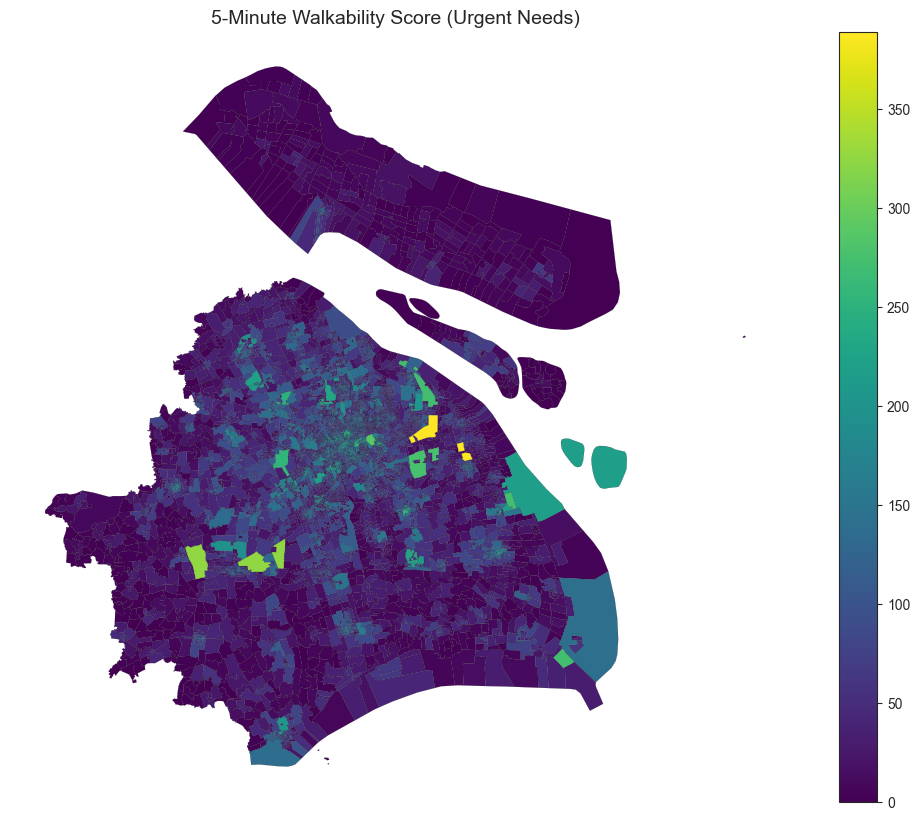

In [9]:
# Plot 5-minute walkability score by village
ax = villages.set_geometry('geometry').plot(
    column='5min',
    cmap=sns.color_palette("viridis", as_cmap=True),
    figsize=(15, 10),
    legend=True,
    edgecolor='black',
    linewidth=0.1
)
plt.title('5-Minute Walkability Score (Urgent Needs)', fontsize=14)
plt.axis('off')
plt.show()


In [10]:
# Select POIs relevant for mid-range services (10-minute walk)
pois_10min = pois[
    (pois['typecode'] == '080101') |  # bus stations
    (pois['typecode'] == '140800') |  # sports facilities
    (pois['typecode'] == '141203')    # community centers
]

# Check number of POIs selected
pois_10min['typecode'].value_counts()


typecode
141203    655
080101    481
140800    236
Name: count, dtype: int64

In [11]:
# Perform spatial join between 10-minute buffers and relevant POIs
villages_10min = villages.set_geometry('buffer_10').sjoin(pois_10min.to_crs(villages.crs))

# Count POIs per village
poi_count_10min = villages_10min.groupby(villages_10min.index).count()

# Store result in new column
villages['10min'] = poi_count_10min['ad_code']

# Fill missing values with 0
villages['10min'] = villages['10min'].fillna(0)


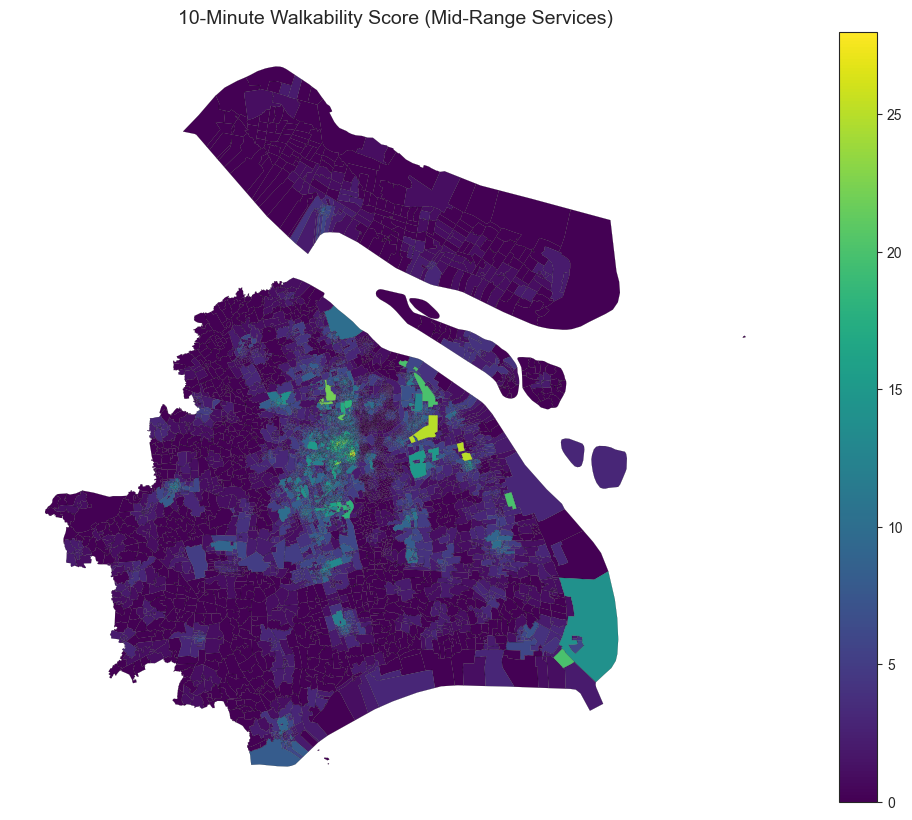

In [12]:
# Plot 10-minute walkability score by village
ax = villages.set_geometry('geometry').plot(
    column='10min',
    cmap=sns.color_palette("viridis", as_cmap=True),
    figsize=(15, 10),
    legend=True,
    edgecolor='black',
    linewidth=0.1
)
plt.title('10-Minute Walkability Score (Mid-Range Services)', fontsize=14)
plt.axis('off')
plt.show()


In [13]:
# Select POIs relevant for large-scale services (15-minute walk)
pois_15min = pois[
    (pois['typecode'] == '060400') |  # hospitals
    (pois['typecode'] == '090000') |  # financial institutions
    (pois['typecode'] == '141202')    # shopping malls
]

# Display how many POIs are selected
pois_15min['typecode'].value_counts()


typecode
060400    5594
090000    5228
141202     717
Name: count, dtype: int64

In [14]:
# Perform spatial join between 15-minute buffers and relevant POIs
villages_15min = villages.set_geometry('buffer_15').sjoin(pois_15min.to_crs(villages.crs))

# Count POIs per village
poi_count_15min = villages_15min.groupby(villages_15min.index).count()

# Store the result in a new column
villages['15min'] = poi_count_15min['ad_code']

# Fill NaNs with 0
villages['15min'] = villages['15min'].fillna(0)


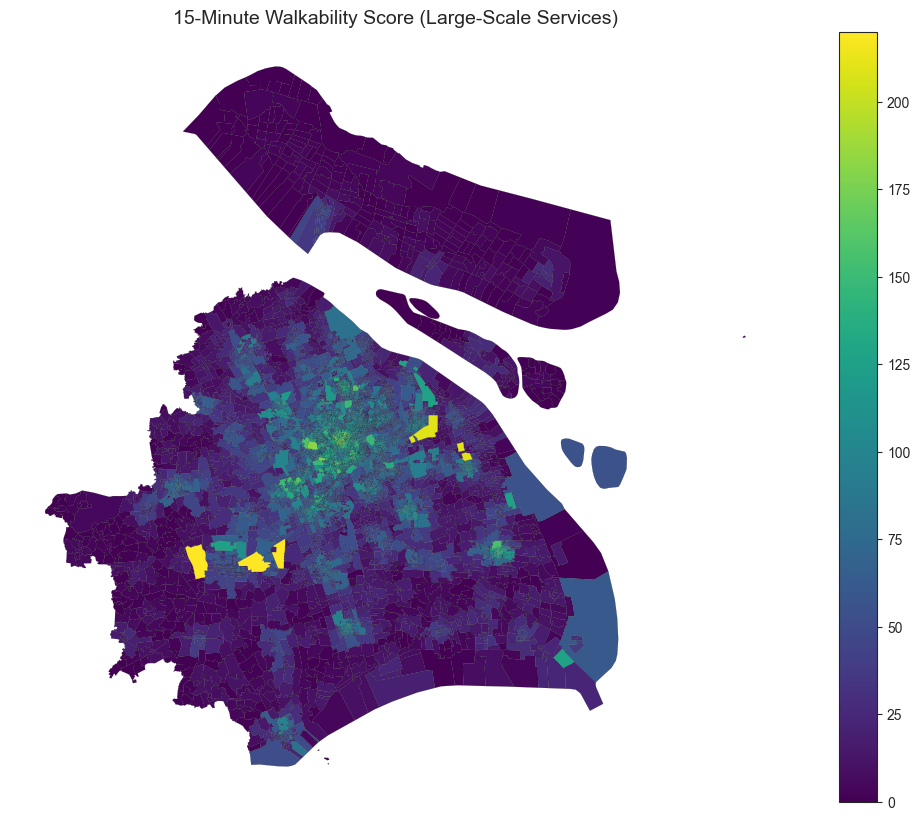

In [15]:
# Plot 15-minute walkability score by village
ax = villages.set_geometry('geometry').plot(
    column='15min',
    cmap=sns.color_palette("viridis", as_cmap=True),
    figsize=(15, 10),
    legend=True,
    edgecolor='black',
    linewidth=0.1
)
plt.title('15-Minute Walkability Score (Large-Scale Services)', fontsize=14)
plt.axis('off')
plt.show()


In [16]:
# Normalize the walkability scores using MinMaxScaler
scaler = MinMaxScaler()

villages['5min_scaled'] = scaler.fit_transform(villages[['5min']])
villages['10min_scaled'] = scaler.fit_transform(villages[['10min']])
villages['15min_scaled'] = scaler.fit_transform(villages[['15min']])

# Calculate final composite score
villages['walkability_score'] = (
    villages['5min_scaled'] +
    villages['10min_scaled'] +
    villages['15min_scaled']
)


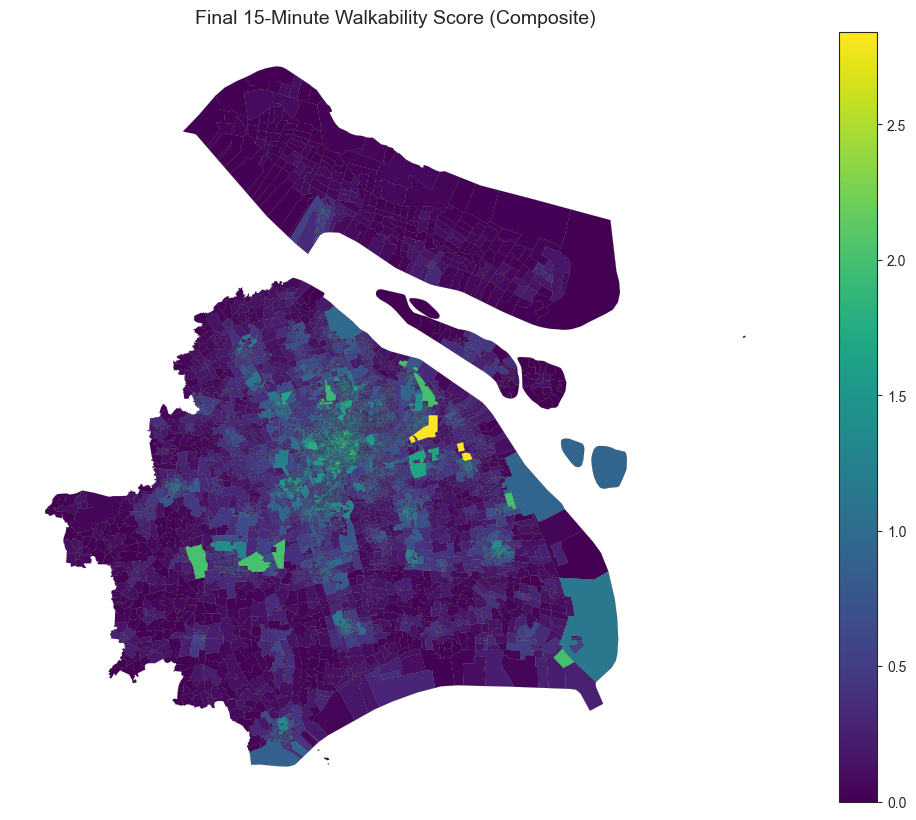

In [17]:
# Plot the final walkability score
ax = villages.set_geometry('geometry').plot(
    column='walkability_score',
    cmap=sns.color_palette("viridis", as_cmap=True),
    figsize=(15, 10),
    legend=True,
    edgecolor='black',
    linewidth=0.1
)
plt.title('Final 15-Minute Walkability Score (Composite)', fontsize=14)
plt.axis('off')
plt.show()


# Conclusion

The analysis of 15-minute walkability in Shanghai reveals significant spatial inequalities in the distribution of essential services. By combining walking buffers (5, 10, and 15 minutes) with point of interest (POI) data, we computed a composite accessibility score for each village.

## Key Takeaways:
- **Central villages** (especially in the inner districts) show high accessibility to daily, mid-range, and large-scale services.
- **Peripheral and suburban villages** tend to have low scores, indicating a lack of nearby facilities.
- The results highlight **priority areas** where urban planning should focus on improving local infrastructure and service coverage.

This walkability metric offers a valuable tool to support more equitable, sustainable, and human-centered urban development in Shanghai.
